# EDA Samuel — impact, threat rank, dan perubahan antarcycle

**Research question yang dipilih pengguna:** Apakah hubungan antara `impact_load` dan `threat_rank` mengalami perubahan antarperiode `cycle_code`, meskipun distribusi `threat_rank` relatif stabil?

## tl;dr

Pada snapshot data yang diaudit, jawabannya **ya secara deskriptif**. Hubungan awal lebih lemah; perbedaan bertahan pada beberapa pembagian periode dan setelah komposisi impact × entry_friction dibuat sama. Perubahan tidak monotonik dan distribusi kondisional dapat bergeser berlawanan arah. Mean target yang stabil hampir mengikuti konsekuensi matematis geometri percentile per-cycle; itu bukan bukti hubungan fitur stabil.

Milestone ini hanya EDA. Model, fitur final, validation protocol dan eksperimen masih menunggu review. Angka dinamis dihitung di bawah; narasi mengacu SHA input yang dicatat.

## Context & Methods

### Background dan asumsi

TP1 memakai target impact yang terkonsentrasi dan menekankan conditional median serta evaluasi target-region. TP2 memiliki target threat yang jauh lebih padat. Tujuan EDA adalah membedakan perubahan marginal, perubahan komposisi fitur dan perubahan distribusi kondisional.

- Unit analisis: satu record train; seluruh 33 cycle digunakan. Cycle lebih besar dideskripsikan lebih baru dalam materi, tetapi kalender absolut tidak diketahui.
- Tiga blok utama adalah 11 **cycle unik** berturut-turut; sensitivitas memakai 2 dan 4 blok serta pembobotan cycle yang sama. Tidak memotong cycle menjadi quantile baris.
- Common support dipilih dari hitungan exact impact × EF: minimal 30 baris di setiap blok. Ulangi threshold impact-only 20/50/100. Bobot tetap berasal dari pooled counts fitur, bukan target.
- Kuantil/IQR adalah sebaran observasi, bukan confidence interval. Resampling cycle bersifat sensitivity, tidak menangani serial dependence.
- Tidak ada target test, target-derived feature, model fitting, atau inferensi kausal. Diagnostic percentile memakai target terhadap dirinya sendiri, hanya untuk interpretasi skala.
- Ilustrasi dan threshold dipilih dalam EDA; bukan praregistrasi. Source code perhitungan ada di `src/data/temporal_eda.py`, `composition_eda.py`, dan `formal_eda.py`.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT/'src/utils/paths.py').is_file() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT/'src/utils/paths.py').is_file():
    raise FileNotFoundError('Open notebook inside the TP2 repository.')
sys.path.insert(0, str(ROOT))
from src.data.formal_eda import run_formal_eda
bundle = run_formal_eda()
t, c, s = bundle['temporal'], bundle['composition'], bundle['summary']
periods = {p['label']: f"{p['cycle_min']}-{p['cycle_max']}" for p in c['periods']}
print('Status:', s['status'])
print('Train SHA-256:', s['train_sha256'])

Status: SAMUEL_EDA_MILESTONE_COMPLETE_REVIEW_REQUIRED_BEFORE_MODELING
Train SHA-256: 756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10570e55ff6db0e0f082


## Data dan persiapan khusus EDA

Raw hanya dibaca. Analisis memakai impact, target, cycle, EF, serta indikator missing sebagai sensitivity. Tidak melakukan imputasi atau normalisasi target karena kolom utama lengkap dan finite; unsupported cells tetap dilaporkan sebagai exclusion. Test hanya untuk schema/ID, bukan hubungan target.

In [2]:
display(pd.DataFrame([{'split': role, 'rows': v['rows'], 'file': v['file'], 'sha256': v['sha256']}
                      for role,v in t['input_manifest'].items()]))
display(pd.DataFrame([t['schema_validation']]))

,split,rows,file,sha256
0,train,50608,Train.csv,756523ff8156a9cd776e52249f7e2a8f23dcec432b8d10...
1,test,29421,Test.csv,4e6c381d582ed24f92d17f620f4f0ad25e2e0def29eb57...
2,sample,29421,SampleSubmission.csv,63a51f4b7dfbb0eec9800099407abd8be14d25ec18a533...


,train_has_threat_rank,train_columns_absent_from_test,sample_test_id_order_match,analysis_rows_complete,analysis_rows_dropped_missing_or_nonfinite
0,True,[threat_rank],True,50608,0


## Results — 1. Seluruh cycle dan kestabilan marginal

Garis menunjukkan koefisien dan quantile aktual per cycle. Perubahan coefficient bukan structural-break test. Perhatikan fluktuasi setelah periode awal dan ukuran sampel setiap cycle pada table evidence JSON.

,cycle_code,n,pearson,spearman,target_mean,target_median,target_p10,target_p90
0,47,1342,0.4487,0.4148,50.0373,50.0559,10.0670,90.0074
1,48,977,0.5123,0.4844,50.0512,52.0983,10.0921,90.0102
2,49,1255,0.4541,0.4284,50.0398,50.0000,9.7610,90.0080
3,50,1111,0.4904,0.4737,50.0450,50.0450,10.0810,90.0090
4,51,1535,0.5482,0.5343,50.0326,50.0326,10.0717,90.0065
5,52,1565,0.4756,0.4534,50.0319,50.0319,10.0958,90.0064
6,53,1371,0.4805,0.4406,50.0365,50.0365,10.0656,90.0073
7,54,1256,0.5147,0.4940,50.0398,50.0398,9.9522,89.9482
8,55,1608,0.4472,0.4386,50.0311,50.0311,9.9813,89.9876
9,56,564,0.6511,0.6344,50.0887,50.1330,10.2837,89.8936


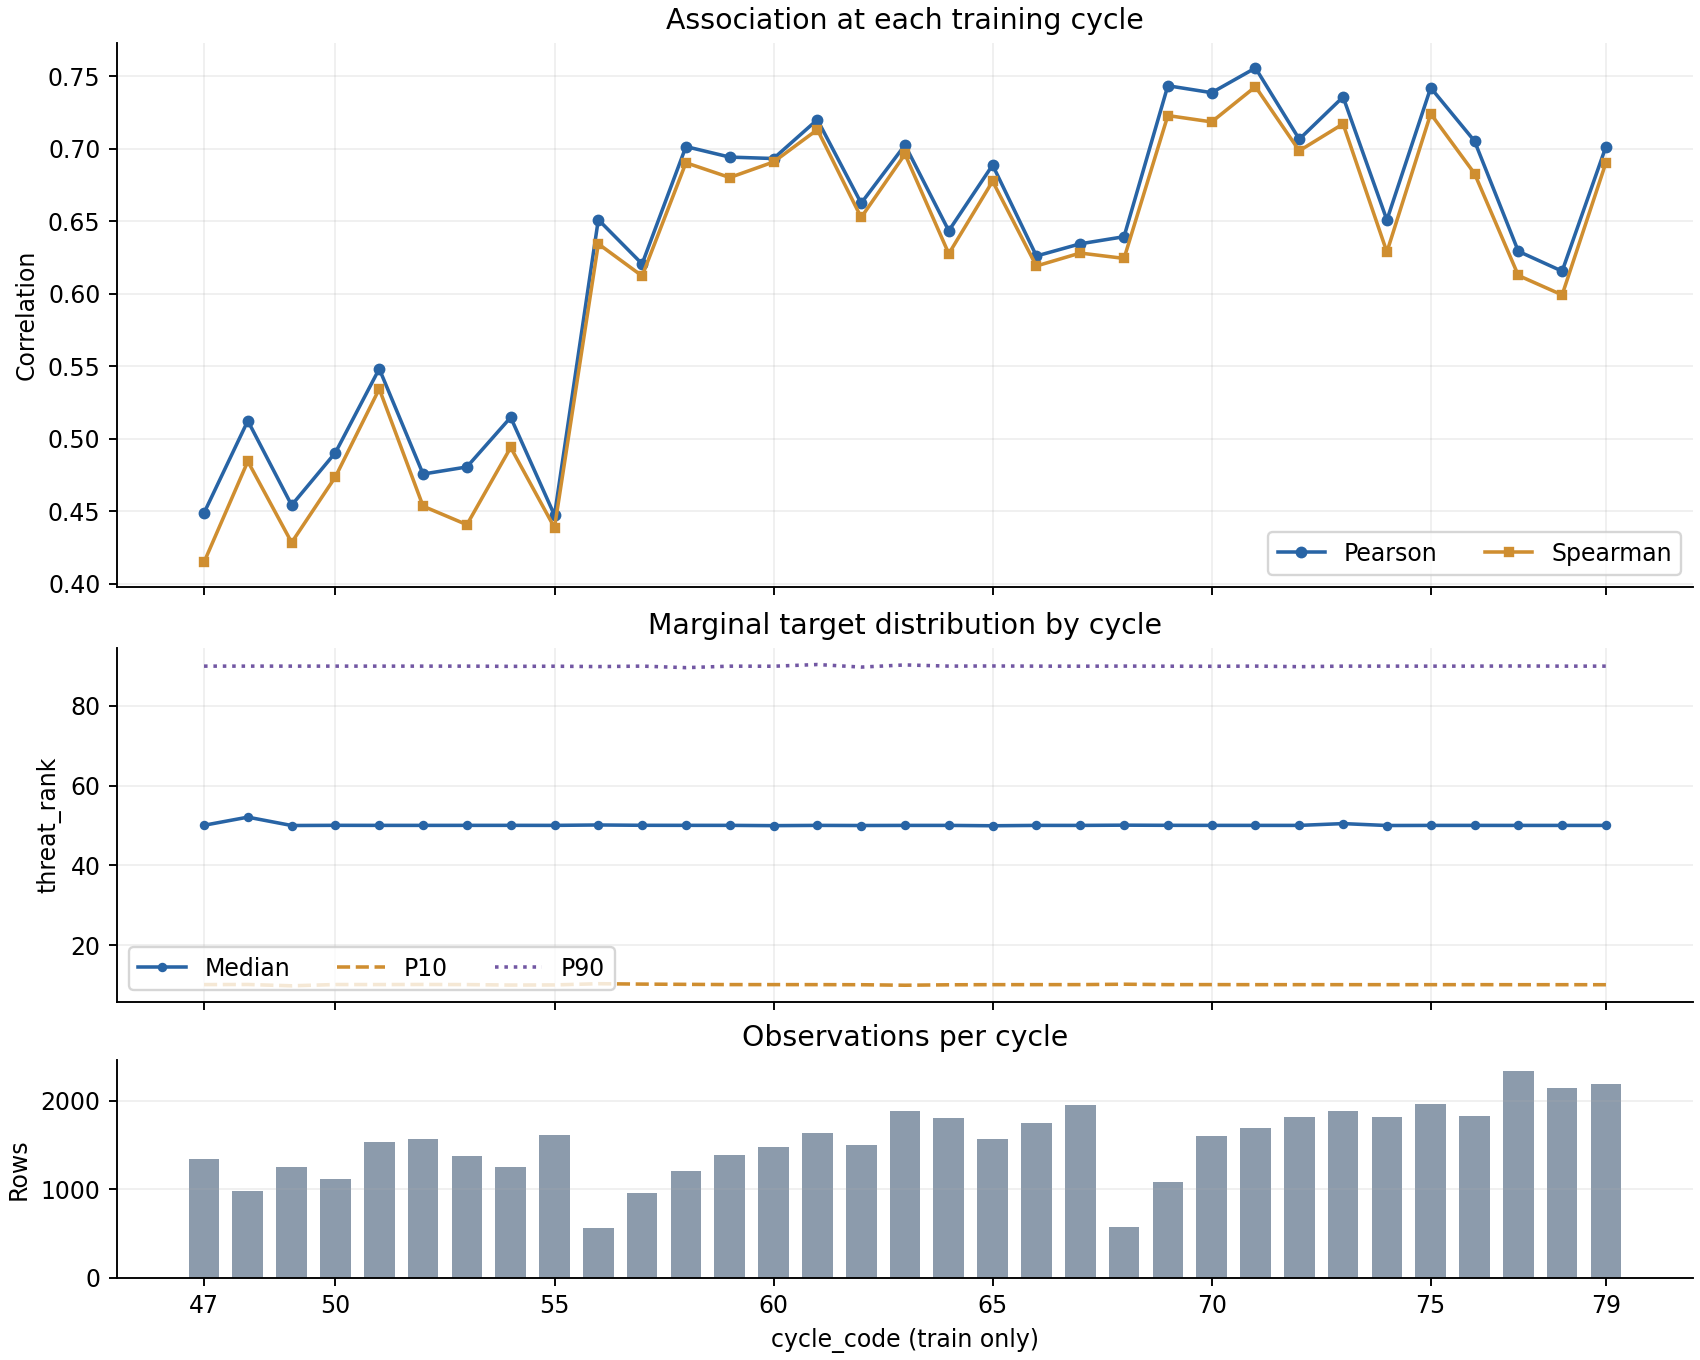

In [3]:
cycles = pd.DataFrame(t['cycles'])
display(cycles[['cycle_code','n','pearson','spearman','target_mean','target_median','target_p10','target_p90']].round(4))
display(Image(filename=str(ROOT/'reports/eda/temporal_per_cycle.png'), alt='All 33 cycle correlations, target quantiles and observation counts'))

**Interpretasi:** periode akhir umumnya mempunyai asosiasi lebih kuat, tetapi tidak setiap cycle naik. Cycle 55→56 menunjukkan perubahan lokal besar dengan sampel cycle 56 lebih kecil; satu perubahan ini tidak membuktikan breakpoint. Marginal rank yang hampir tetap perlu dibaca bersama diagnostic skala di bagian berikutnya.

### Robustness terhadap pembagian periode dan unequal sample size

In [4]:
rows = []
for count, result in t['partition_sensitivity'].items():
    for b in result['blocks']:
        rows.append({'blocks': int(count), 'cycles': f"{b['cycle_min']}-{b['cycle_max']}", 'n': b['n'],
                     'Pearson pooled': b['pooled_pearson'], 'Spearman': b['pooled_spearman'],
                     'Pearson equal-cycle': b['equal_cycle_mean_pearson']})
display(pd.DataFrame(rows).round(4))
loo = t['leave_one_cycle_out_endpoint_sensitivity']
boot = t['primary_first_vs_last']['cycle_cluster_resampling']
display(pd.DataFrame([{'primary Pearson delta': t['primary_first_vs_last']['observed_pearson_delta_late_minus_early'],
    'LOO delta min': min(v['delta_pearson_without_cycle'] for v in loo),
    'LOO delta max': max(v['delta_pearson_without_cycle'] for v in loo),
    'resampling P2.5': boot['resampled_delta_percentile_2_5'],
    'resampling P97.5': boot['resampled_delta_percentile_97_5']}]).round(4))

,blocks,cycles,n,Pearson pooled,Spearman,Pearson equal-cycle
0,2,47-63,22627,0.5794,0.5626,0.5775
1,2,64-79,27981,0.6827,0.6676,0.6848
2,3,47-57,13546,0.4994,0.4773,0.5130
3,3,58-68,16736,0.6722,0.6631,0.6733
4,3,69-79,20326,0.6964,0.6798,0.7022
5,4,47-55,12020,0.4830,0.4606,0.4857
6,4,56-63,10607,0.6845,0.6754,0.6807
7,4,64-71,12028,0.6827,0.6699,0.6837
8,4,72-79,15953,0.6827,0.6663,0.6858


,primary Pearson delta,LOO delta min,LOO delta max,resampling P2.5,resampling P97.5
0,0.197,0.1885,0.2063,0.151,0.2365


**Interpretasi:** pola first-to-last bertahan pada 2/3/4 blok dan equal-cycle mean; bukan hanya bobot cycle besar. Leave-one-cycle-out tidak menghilangkan arah perbedaan. Rentang resampling adalah sensitivity kondisional pada cycle yang teramati, **bukan CI atau forecast interval**; serial dependence tidak diatasi.

## Results — 2. Apakah hanya perubahan komposisi EF?

Bandingkan pooled, EF strata, dan distribusi exact impact × EF yang dibuat sama. Bobot berdasarkan hitungan pada common support, bukan hasil target; coverage membatasi populasi yang dapat dijelaskan.

In [5]:
rows = []
for p in periods:
    v = c['correlations']['by_period'][p]
    w = c['correlations']['common_impact_ef_distribution_weighted'][p]
    rows.append({'cycles': periods[p], 'pooled': v['pooled']['pearson_r'],
        'EF0': v['entry_friction_strata']['0']['pearson_r'],
        'EF1': v['entry_friction_strata']['1']['pearson_r'],
        'fixed impact x EF': w['pearson_r'], 'retained n': w['n_rows'], 'effective n': w['effective_n']})
display(pd.DataFrame(rows).round(4))
display(pd.DataFrame(s['context']['common_support_tail_coverage']))
print('Common joint cells:', c['support_selection']['common_impact_x_friction_cell_count'])
print('Both EF categories supported at this many common impact levels:',
      c['entry_friction_common_support_positivity']['common_impact_levels_with_both_friction_levels_supported_each_period'])

,cycles,pooled,EF0,EF1,fixed impact x EF,retained n,effective n
0,47-57,0.4994,0.3663,0.3855,0.5244,12969,12556.8714
1,58-68,0.6722,0.5397,0.4966,0.6617,16015,15795.5344
2,69-79,0.6964,0.5385,0.6251,0.6837,19646,19314.9671


,retained_common_support,n,low_tail_count_le5,high_tail_count_ge95,mean,median
0,True,48630,2345,2499,50.242042,50.2787
1,False,1978,182,61,44.883466,43.4625


Common joint cells: 33
Both EF categories supported at this many common impact levels: 3


**Interpretasi:** asosiasi tetap lebih kuat pada blok akhir ketika impact × EF mix dibuat sama. EF0 hampir datar setelah blok tengah, sedangkan EF1 masih menguat. Ini belum causal adjustment; hanya tiga common impact levels mempunyai kedua EF dengan support memadai pada semua blok. Common support mencakup 96,09% baris tetapi mengecualikan low-tail lebih banyak secara proporsional daripada high-tail.

## Results — 3. Distribusi kondisional berubah dengan arah berbeda

Contoh impact dipilih setelah discovery untuk menjelaskan bentuk perubahan. Nilai impact dan EF sama di setiap blok; P10/P90/IQR menunjukkan spread aktual, bukan uncertainty of the median. Semua common cells tetap disimpan dalam JSON pendukung.

,impact,cycles,n,median,P10,P90,IQR,high-tail share
0,154.0178,47-57,1498,83.4860,54.4951,98.1975,26.2471,0.2356
1,154.0178,58-68,2698,86.2560,59.3369,98.2250,17.5432,0.2209
2,154.0178,69-79,3108,89.9640,71.8050,98.3469,14.0799,0.2825
3,85.9730,47-57,1016,34.6066,6.4742,70.5423,35.6856,0.0030
4,85.9730,58-68,1072,26.4333,3.9831,53.6610,31.0152,0.0009
5,85.9730,69-79,1633,20.0110,6.2673,60.2410,37.1156,0.0000


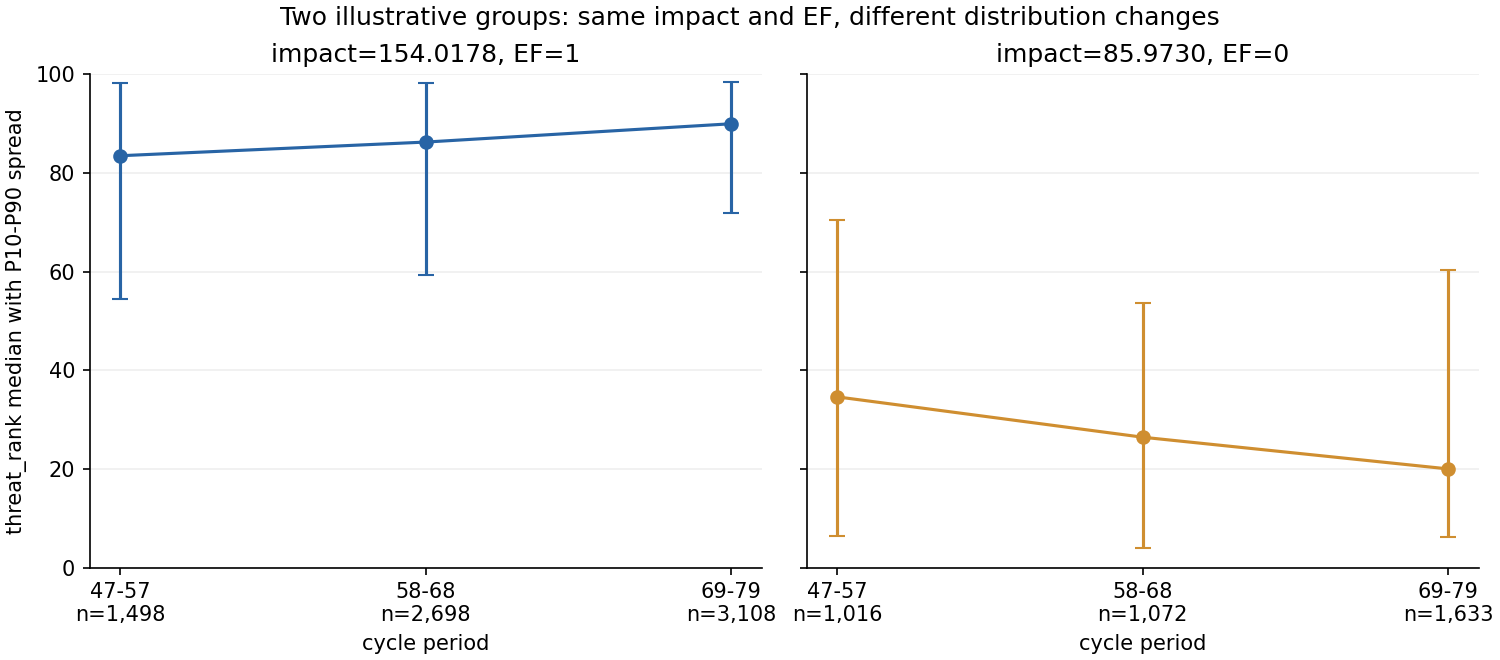

In [6]:
rows = []
for level in c['headline_exact_impact_profiles']:
    for p,v in level['periods'].items():
        rows.append({'impact': level['impact_load'], 'cycles': periods[p], 'n': v['n'],
            'median': v['median'], 'P10': v['p10'], 'P90': v['p90'], 'IQR': v['iqr'],
            'high-tail share': v['tail_ge_95_count']/v['n']})
display(pd.DataFrame(rows).round(4))
display(Image(filename=str(ROOT/'reports/eda/formal_selected_conditional.png'), alt='Two illustrative exact impact and EF groups with common-scale median and P10-P90 changes'))

**Interpretasi:** pada impact 154,0178 / EF1, median naik tetapi P90 hampir tetap, sementara lower quantile naik kuat dan IQR menyempit. Pada 85,9730 / EF0 median turun; perubahan tidak berupa global shift yang sama. Pembalikan median 110,5078 vs 134,6432 dipengaruhi EF mixture, tetapi EF stratification tidak membuat semua median contrast monotonik. EF1 tidak tersedia pada impact 134,6432 dan EF0 pada 110,5078 berukuran kecil; lihat report pendukung sebelum menafsirkan “efek impact”.

### Mean stabil dapat menutupi perubahan yang saling meniadakan

,late_minus_early,composition_effect,within_stratum_effect,identity_residual
0,0.16755,1.050359,-0.882808,-0.0


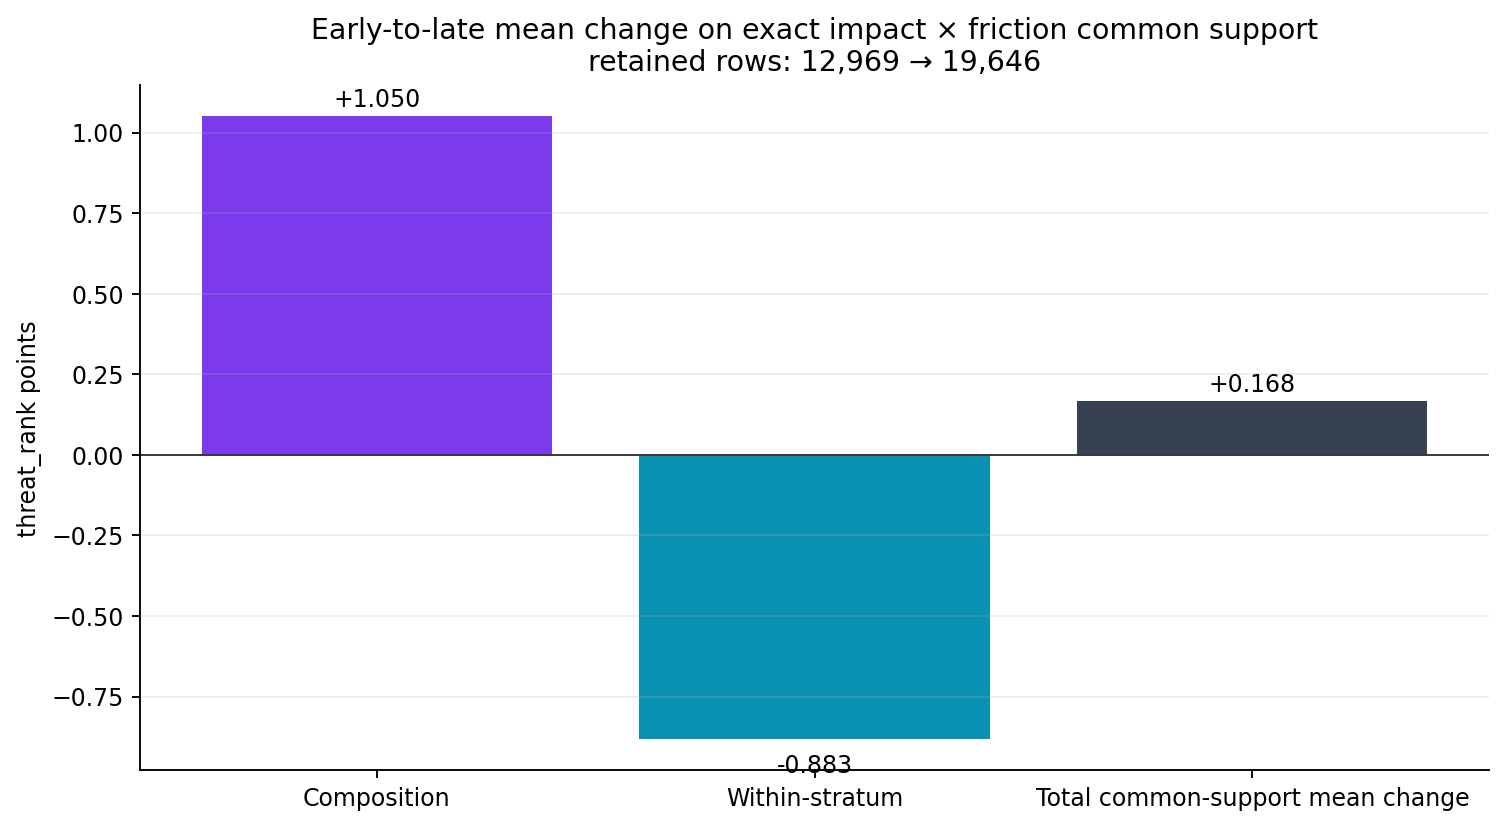

In [7]:
d = c['mean_decomposition']['symmetric_decomposition']
display(pd.DataFrame([{k:d[k] for k in ('late_minus_early','composition_effect','within_stratum_effect','identity_residual')}]).round(6))
display(Image(filename=str(ROOT/'reports/eda/composition_mean_decomposition.png'), alt='Arithmetic decomposition of common-support mean change into composition and within-stratum terms'))

**Interpretasi:** komponen composition dan within-stratum berlawanan tanda. Ini decomposition aritmetika mean pada **retained common support**, bukan penjelasan kausal dan bukan decomposition Pearson. Denominator berbeda dari seluruh train, sehingga jangan menyamakan net mean change di sini dengan mean global.

## Results — 4. Marginal stabil dan geometri target

Seluruh label cocok dengan average percentile rank dari label itu sendiri di setiap cycle (pembulatan 4 desimal). Conditional pada identitas numerik ini, mean average rank selalu `(n+1)/2`, sehingga mean score sebelum rounding menjadi `50+50/n`. Ini menjelaskan mengapa mean hampir 50; bukan bukti source formula atau kestabilan risiko laten.

In [8]:
v = t['marginal_vs_association']
display(pd.DataFrame([{'rank matches': v['average_rank_percentile_matches'],
  'rows': v['average_rank_percentile_rows'], 'max mean residual from 50+50/n': v['max_abs_target_mean_minus_rank_implied_mean'],
  'max two-sided uniform ECDF distance': v['uniform_ks_two_sided_distance_max_cycle']}]))
print('In-sample nonlinear association diagnostics; NOT model performance:')
display(pd.DataFrame([t['nonlinear_association_diagnostics']]).drop(columns=['interpretation']))

,rank matches,rows,max mean residual from 50+50/n,max two-sided uniform ECDF distance
0,50608,50608,0.000003,0.022333


In-sample nonlinear association diagnostics; NOT model performance:


,distinct_impact_levels,eta_squared_exact_impact,pearson_squared,spearman
0,80,0.502596,0.405791,0.621102


**Interpretasi:** marginal hampir uniform konsisten dengan skala relatif per-cycle dan ties. Ia tidak memberi bukti tambahan bahwa conditional relationships stabil. Eta² exact-impact lebih besar daripada Pearson², sehingga grouped shape dan mixture layak diperiksa; itu bukan predictive R². Jangan memakai label/rank target sebagai fitur, meranking ulang target perfold, atau memakai test labels.

## Robustness dan keterbatasan tambahan

Missingness relevan karena TP1 memakai fallback ketika text kosong. Berikut hanya sensitivity hubungan yang sama pada stream-present/missing, tanpa pipeline text atau klaim nilai tambah feature.

In [9]:
display(pd.DataFrame([v for v in s['context']['missingness_strata'] if v['column']=='signal_stream'])
        [['period','missing','n','share_period','pearson','spearman']].round(4))

,period,missing,n,share_period,pearson,spearman
0,period_1,False,12537,0.9255,0.5111,0.4857
1,period_1,True,1009,0.0745,0.4014,0.4397
2,period_2,False,15664,0.9359,0.6767,0.6670
3,period_2,True,1072,0.0641,0.5982,0.6004
4,period_3,False,19003,0.9349,0.7029,0.6859
5,period_3,True,1323,0.0651,0.5864,0.5698


Arah early-to-late tetap ada pada kedua kelompok stream, tetapi besar coefficient berbeda dan perbandingan belum mengontrol semua fitur. Source meaning threat_rank, ketergantungan record/serial cycle, rare-group exclusions, post-hoc examples dan unknown timing fitur membatasi kesimpulan. Seluruh train sudah dipakai EDA; tidak ada untouched holdout yang diklaim.

## TP1 → TP2 dan modeling directions untuk review

Pelajaran TP1 yang bertahan: periksa distribution, conditional median, tails dan signed error terpisah dari MAE. Phase16 B2 memotivasi regime heterogeneity. Yang berubah: 80 target values TP1 versus 34.333 TP2; exact-score multiclass tidak otomatis relevan. Tidak ada prediction bias TP2 yang sudah diukur.

Rancangan diskusi pada `docs/REGRESSION_EXPERIMENT_REVIEW.md`: baseline global/group median, nonlinear impact × EF, ablation cycle/history, conditional quantiles, relative-rank evaluation dan text/missingness ablation. Semua masih **belum dijalankan**. Forward validation dengan cycle utuh lebih dekat ke test80–91; random split hanya pembanding diagnostik. Metric resmi dan windows harus direview.

## Final findings dan titik review

Pertanyaan utama terjawab secara deskriptif: perbedaan hubungan terlihat meskipun marginal stabil, dan tidak seluruhnya dijelaskan komposisi impact × EF. Perubahan tidak monotonik, berbeda antarregime, dan dapat saling meniadakan di mean global. Kestabilan marginal sebagian besar konsisten dengan konstruksi skala rank yang teramati, tanpa membuktikan mekanisme sumber atau drift kausal.

**Berhenti di sini:** review hasil EDA, metric/validation protocol, fitur allowlist dan eksperimen putaran pertama bersama pengguna. Tidak ada final-model selection, training, tuning, ensemble atau Kaggle submission. Laporan utama: `reports/eda/SAMUEL_FORMAL_EDA.md`.